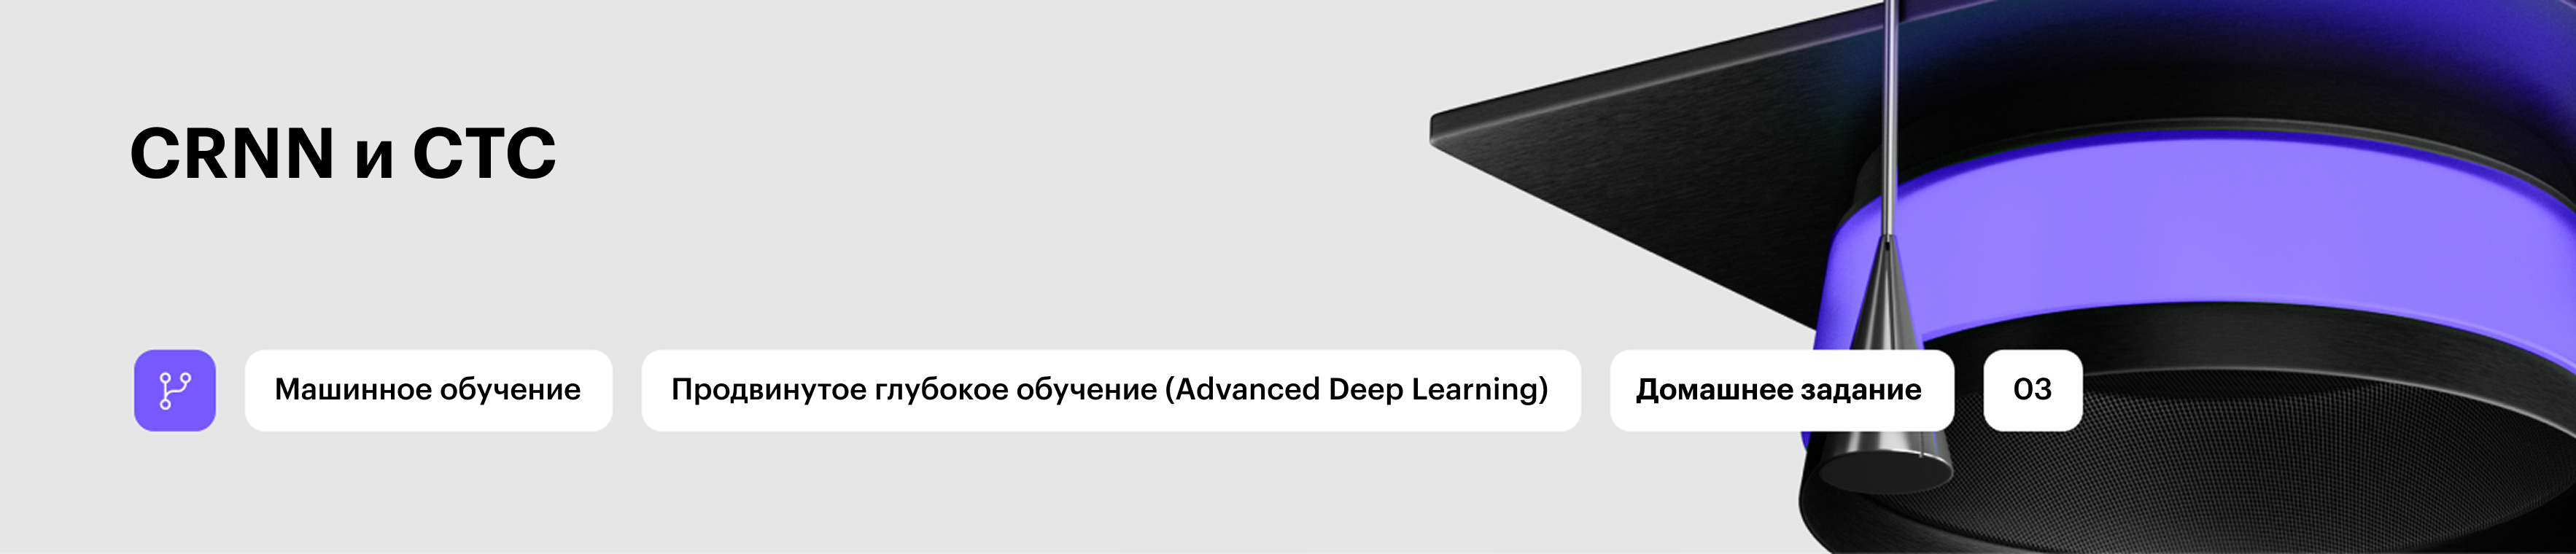

## Домашнее задание 3. Распознавание текста на изображениях. Часть 1

<img src="...
" alt="drawing" width="1000"/>


# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используй данный шаблон.</font>**

    ✅ Можно добавлять новые ячейки любых типов.
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий.


🔷 **<font color='plum'>При оценивании задач учитывается код.</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами «Your code here» / «Твой код» и аналогичными.
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов.
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно.

🔷 **<font color='plum'>При оценивании задач учитываются выводы.</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами «Вывод» / «Ответ на вопрос» / «Твой текст» и аналогичными.
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать Markdown, LaTeX).
    ✅ Сопутствующие изображения, графики, таблички приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл.

----
## <font color='OrangeRed'>**Внимание! Аларм! Ахтунг!**</font>

* Данный ноутбук желательно выполнять на внутренней платформе <font color='DarkSeaGreen'>**jupyter.culab**</font> ЦУ.

* Работоспособность данного ноутбука проверена именно на <font color='DarkSeaGreen'>**jupyter.culab**</font>, работоспособность «из-под коробки» на других платформах мы не гарантируем.

* Ты можешь делать задание у себя локально / Google Colab / Kaggle и пр. при желании, однако работать с дополнительными файлами и настраивать окружение придётся самостоятельно.

* Подробнее об использовании внутренней платформы читай в описании курса.

### <font color='DarkOrange'> **Основная часть [10 баллов]** </font>

---

- Набор данных:

    состоит из 10327 `простых` изображений и 14222 `сложных` изображений, имя файла содержит информацию о тексте регистрационного знака (пример: `rus_14716_X222PP150.png`, ..., `rus_14732_Y940KC197.png`).
      
- Задача:

    требуется разработать загрузчик данных,

    требуется разработать модель,

    требуется загрузить веса модели и обработать 9 случайных `простых` изображений.

    
    

---

Установим и импортируем необходимые модули.

In [1]:
#! pip install albumentations
import importlib.util
import subprocess
import sys

requirements = {"albumentations":"albumentations>=2.0.8,<3", "torchvision":"torchvision>=0.29.2,<1"}
missing = [spec for module, spec in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [2]:
import torchvision.transforms as transforms
import torchvision.datasets   as datasets
import torch.nn.functional    as F
import torchvision.models     as models

import matplotlib.pyplot      as plt
import torch.optim            as optim
import torch.nn               as nn

import torchvision
import colorsys
import random
import torch
import glob
import json
import time
import tqdm
import cv2
import os
import re

from torchvision.transforms.functional import convert_image_dtype, resize
from torch.utils.data   import DataLoader
from collections        import namedtuple
from matplotlib.patches import Polygon
from matplotlib         import patches, lines
from PIL                import Image

from torchvision.io import read_image
from string import digits, ascii_uppercase

import albumentations as alb
import numpy          as np
import scipy          as sp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

import warnings
warnings.filterwarnings('ignore')

In [3]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

SEEDS = [42]
DEVICE = torch.device(os.environ.get("DEVICE", "cuda" if torch.cuda.is_available() else "cpu"))
seed_everything(SEEDS[0])
print("Device:", DEVICE)
print("NumPy:", np.__version__, "PyTorch:", torch.__version__)

Device: cuda
NumPy: 2.2.6 PyTorch: 2.14.1+cu130


### Набор данных

Набор данных представляет собой размеченные изображения регистрационных знаков РФ, собранных из интернета либо сгенерированных автоматически.
В названии файла закодирован текст регистрационного знака.

```
rus_14664_C273XC190.png
rus_14665_T416OK777.png
rus_14666_E336HO197.png
rus_14667_T517CP197.png
rus_14671_X888EP150.png
rus_14672_O486ET777.png
rus_14673_C446XA190.png
rus_14677_M251EB71.png
rus_14678_C411XH777.png
rus_14679_T395XY35.png
rus_14682_Y689EC35.png
rus_14684_C197CC197.png
```

При решении задачи нам надо зафиксировать словарь символов, которые будет предсказывать наша модель. Регистрационные знаки состоят из букв `EKMHOPCTYX` и цифр `0123456789`, а также сервисного символа `-`, смысл которого ты узнаешь позднее. Сервисный символ для удобства мы поместим в начале нашего словаря символов или алфавита.

In [4]:
ABC = "-0123456789ABEKMHOPCTYX"

In [5]:
#!mkdir -p data
#!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/seminars/license-plate-recognition.zip
#!unzip -o license-plate-recognition.zip -d data >/dev/null
#!rm license-plate-recognition.zip

In [6]:
PATH_TO_TRAIN_SIMPLE_DATA  = "./data/train/train/simple"  #Простые изображения
PATH_TO_TRAIN_COMPLEX_DATA = "./data/train/train/complex" #Сложные изображения

In [7]:
!ls -l $PATH_TO_TRAIN_SIMPLE_DATA | head

total 123336
-rw-r--r-- 1 mlcore mlcore   5296 Nov 18  2024 rus_00003_B026CO90.png
-rw-r--r-- 1 mlcore mlcore   8208 Nov 18  2024 rus_00004_C421PA35.png
-rw-r--r-- 1 mlcore mlcore  10188 Nov 18  2024 rus_00005_B696TT35.png
-rw-r--r-- 1 mlcore mlcore   3746 Nov 18  2024 rus_00006_B667AE35.png
-rw-r--r-- 1 mlcore mlcore   7762 Nov 18  2024 rus_00009_Y487BY35.png
-rw-r--r-- 1 mlcore mlcore  10917 Nov 18  2024 rus_00014_A991CX35.png
-rw-r--r-- 1 mlcore mlcore   6378 Nov 18  2024 rus_00016_B038HE35.png
-rw-r--r-- 1 mlcore mlcore   9156 Nov 18  2024 rus_00017_P112CK777.png
-rw-r--r-- 1 mlcore mlcore   9489 Nov 18  2024 rus_00019_B944CY197.png
ls: write error: Broken pipe


In [8]:
!ls -l $PATH_TO_TRAIN_COMPLEX_DATA | head

total 457928
-rw-r--r-- 1 mlcore mlcore    7794 Nov 18  2024 rus_00002_E031CM777.png
-rw-r--r-- 1 mlcore mlcore    4581 Nov 18  2024 rus_00006_B973KE35.png
-rw-r--r-- 1 mlcore mlcore   37406 Nov 18  2024 rus_00008_H719AO197.png
-rw-r--r-- 1 mlcore mlcore    8003 Nov 18  2024 rus_00010_P028EK777.png
-rw-r--r-- 1 mlcore mlcore   20886 Nov 18  2024 rus_00011_T867MT35.png
-rw-r--r-- 1 mlcore mlcore    7433 Nov 18  2024 rus_00012_C081PC178.png
-rw-r--r-- 1 mlcore mlcore    7982 Nov 18  2024 rus_00013_T120KB750.png
-rw-r--r-- 1 mlcore mlcore    3124 Nov 18  2024 rus_00016_C821CC197.png
-rw-r--r-- 1 mlcore mlcore   13795 Nov 18  2024 rus_00017_B355BE35.png
ls: write error: Broken pipe


---

### <font color='DarkOrange'> **Разработать загрузчик данных [3 балла]**</font>

In [9]:
from torchvision.transforms.functional import to_pil_image
from torch.utils.data                  import Dataset, DataLoader

from PIL import Image

class RecognitionDataset(Dataset):
    def __init__(self, images_pathdir, alphabet, transforms=None):
        super(RecognitionDataset, self).__init__()
        """
        Args:
            images_pathdir (str): Path to directory containing .png images
            alphabet       (str): String of all possible characters (e.g., "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789")
            transforms (callable, optional): Torchvision transforms to apply to each image
        """
        # START YOUR CODE HERE

        self.images_pathdir = images_pathdir
        self.alphabet       = alphabet
        self.transforms     = transforms
        self.image_names, self.texts = self._parse_root_()

        # END YOUR CODE HERE
    def __len__(self):
        """
        Returns the total number of samples in the dataset.

        This is required by PyTorch's DataLoader to determine how many batches
        can be drawn from the dataset.

        Returns:
            int: Number of image-label pairs in the dataset.
        """
        # START YOUR CODE HERE
        #return len(self.images)
        return len(self.texts)
        # END YOUR CODE HERE
    """
    def _parse_root_(self):
        image_names, texts = [], []
        for item in os.listdir(self.images_pathdir):
            print("item=",item)
            image_name = item["file"]
            text = item['text']
            texts.append(text)
            image_names.append(image_name)
        return image_names, texts
    """

    def _parse_root_(self):
        image_names, texts = [], []
        for file_name in sorted(os.listdir(self.images_pathdir)):
            if file_name.endswith(".png"):
                image_names.append(file_name)
                # Извлекаем текст из имени файла без расширения .png
                text = os.path.splitext(file_name)[0]
                texts.append(text)
        return image_names, texts
        
    def __getitem__(self, item):
        """
        Fetches a single data sample from the dataset.

        Args:
            item (int): Index of the sample to retrieve.

        Returns:
            dict: {
             'torch_image': torch.Tensor - transformed image,
             'pil_image'  : PIL.Image - original image (for visualization or debug),
             'seq'        : List[int] - encoded label as sequence of integers,
             'seq_len'    : int - length of the sequence,
             'text'       : str - raw label text
            }
        """
        # START YOUR CODE HERE
        img_path = os.path.join(self.images_pathdir, self.image_names[item])
        #pil_image = Image.open(img_path)
        pil_image = Image.open(img_path).convert("RGB") 
        torch_image = self.transforms(pil_image)
        text = self.texts[item]
        seq = self.text_to_seq(text)
        seq_len = len(seq)
        output = dict(torch_image=torch_image, pil_image=pil_image, seq=seq, seq_len=seq_len, text=text)
        return output
        # END YOUR CODE HERE


    def text_to_seq(self, text):
        """Encode text to sequence of integers.

        Args:
            text - String of text.

        Returns:
            List of integers where each number is index of corresponding characted in alphabet + 1.
        """

        # YOUR CODE HERE
        seq = [self.alphabet.find(c) + 1 for c in text]
        return seq
        # END OF YOUR CODE

In [10]:
from torchvision.transforms.v2 import Resize, ToDtype, ToImage, Normalize, Compose

transforms = Compose([
    ToImage(), ToDtype(torch.float32, scale=True), Resize(size=(32,160)),
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset = RecognitionDataset( PATH_TO_TRAIN_SIMPLE_DATA, alphabet=ABC, transforms=transforms)

In [11]:
x = dataset[0]
print(x.keys())

dict_keys(['torch_image', 'pil_image', 'seq', 'seq_len', 'text'])


In [12]:
print("Image shape:", x["torch_image"].shape)
print("Seq:" , x["seq"], "Seq_len:", x["seq_len"])
print("Text:", x["text"])

Image shape: torch.Size([3, 32, 160])
Seq: [0, 0, 0, 0, 2, 2, 2, 2, 5, 0, 13, 2, 4, 8, 20, 18, 11, 2] Seq_len: 18
Text: rus_00003_B026CO90


---

### <font color='DarkOrange'> **Разработать модель распознавания текста на изображении [4 балла]**</font>

Модель состоит из двух частей: `Encoder` и `Decoder`.
- `Encoder` состоит из набора свёрточных, рекуррентного и полносвязного слоёв.
- `Decoder` состоит из рекуррентного и полносвязного слоёв.

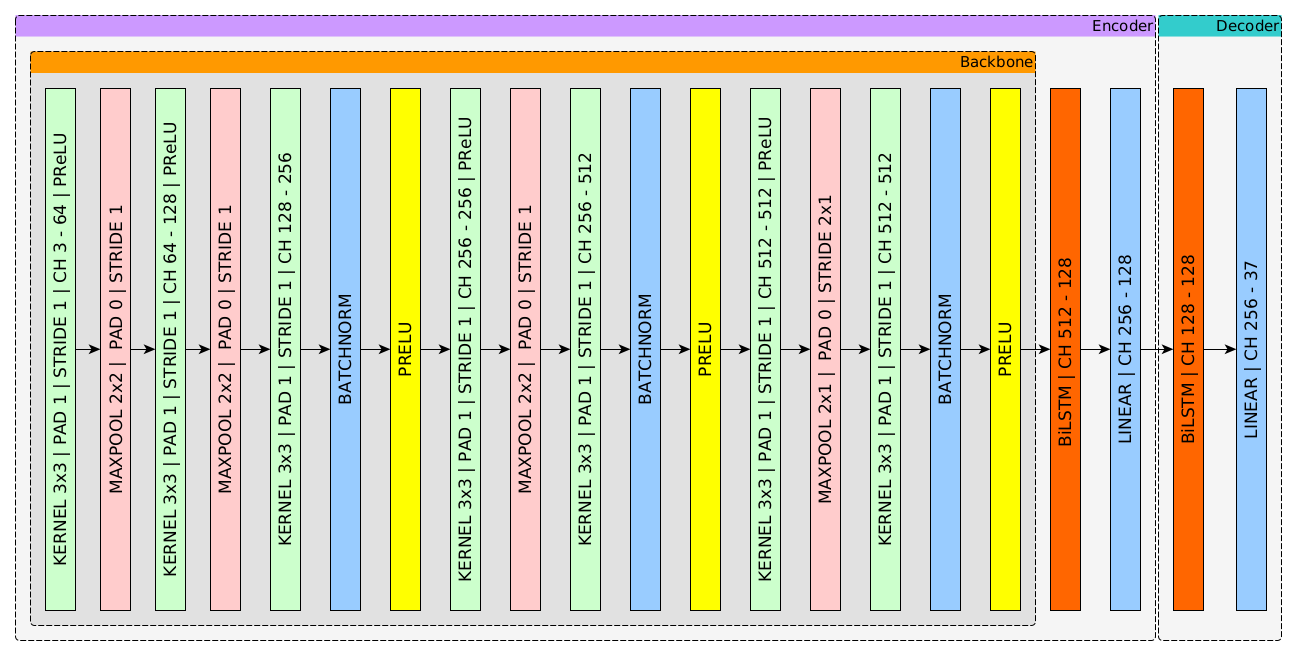

#### Энкодер модели

**Реализовать класс `Encoder` согласно архитектуре. Энкодер будет состоять из свёрточных, рекуррентного и полносвязного слоёв. Отметим, что мы решаем задачу `seq2seq` и в данном случае неважно, как мы обрабатываем последовательность: слева направо или наборот, поэтому в слое `LSTM` `bidirectional`==True.**

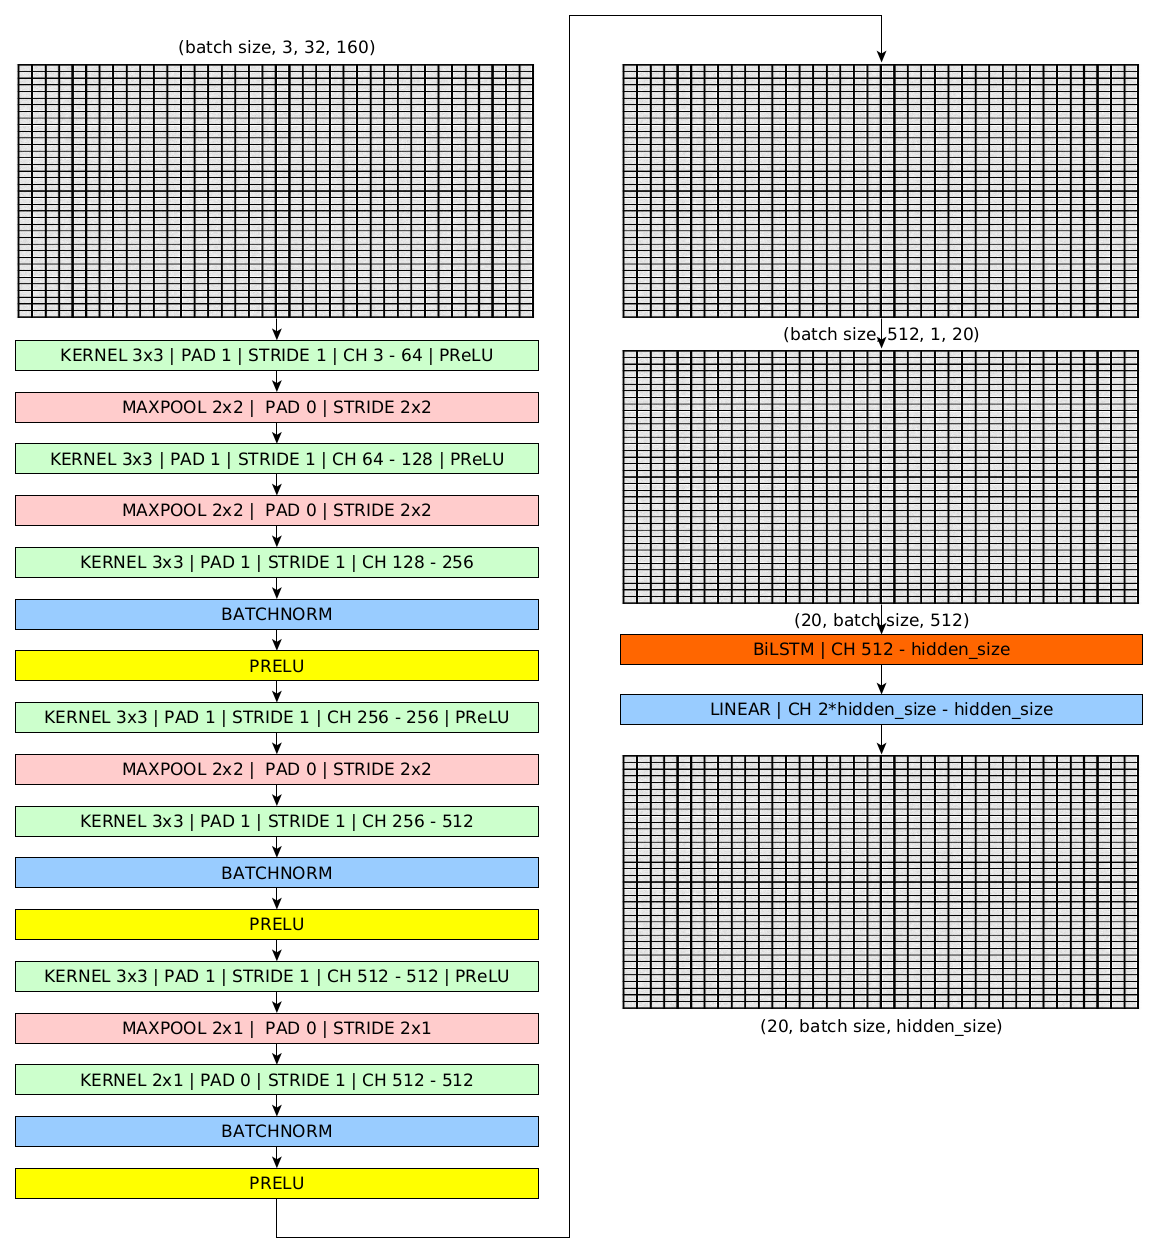

In [13]:
from torch.nn import Module, GRU, LSTM, Sequential, Conv2d, Linear

class Encoder(nn.Module):
    def __init__(self, imgH, nH):
        super(Encoder, self).__init__()
        assert imgH % 16 == 0, 'imgH has to be a multiple of 16'
        self.cnn    = None
        self.rnn    = None
        self.linear = None
        # START YOUR CODE HERE
        self.cnn = nn.Sequential(
            # 64x16x80
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1),
            nn.PReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)),
            
            # 128x8x40
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.PReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)),
            
            # 256x8x40
            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.PReLU(),
            
            # 256x4x20
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            nn.PReLU(),
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=(0, 0)),
            
            # 512x4x20
            nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(512),
            nn.PReLU(),
            
            # 512x2x20
            nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
            nn.PReLU(),
            nn.MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=(0, 0)),
            
            # 512x1x20
            nn.Conv2d(512, 512, kernel_size=(2, 1), stride=1, padding=0),
            nn.BatchNorm2d(512),
            nn.PReLU(),
        )

        self.rnn = nn.LSTM(input_size=512, hidden_size=nH, bidirectional=True)
        self.linear = nn.Linear(nH * 2, nH)
        # END YOUR CODE HERE
    def forward(self, input):
        # START YOUR CODE HERE
        conv = self.cnn( input )
        b, c, h, w = conv.size()
        conv = conv.squeeze(2)
        conv = conv.permute(2, 0, 1) #[w, b, c]
        # END YOUR CODE HERE
        
        rnn_out, _ = self.rnn(conv)
        output = self.linear(rnn_out)
        return output

In [14]:
imgC, imgH, imgW = 3, 32, 160 #Разрешение входного изображения
nH, nL = 512, 1

In [15]:
x = torch.randn(1, 3, 32, 160)
y = Encoder(imgH, nH)(x)

assert y.size() == (20, 1, 512) #(sequence_size, batch_size, hidden_size)

#### Декодер модели

**Реализовать класс `Decoder` согласно архитектуре. Декодер будет состоять из слоёв `LSTM` и `Linear`. Отметим, что мы решаем задачу `seq2seq` и в данном случае неважно, как мы обрабатываем последовательность: слева направо или наборот, поэтому `bidirectional`==True. Выход полносвязного слоя соответствует размеру словаря символов (в нашем случае — 23).**

<img src="...
" alt="drawing" width="800"/>


In [16]:
class Decoder(nn.Module):
    def __init__(self, nIn, nH, nClass):
        super(Decoder, self).__init__()
        self.rnn    = None
        self.linear = None
        ### START YOUR CODE HERE
        self. rnn= nn.LSTM(nIn, nH, num_layers=nL, bidirectional=True)
        self.linear = nn.Linear(2 * nH, nClass)
        ### END YOUR CODE HERE
    def forward(self, input):
        ### START YOUR CODE HERE
        y, _ = self.rnn(input)

        T, b, h = y.size()
        t_rec = y.view(T * b, h)

        output = self.linear(t_rec)  # [T * b, nOut]
        output = output.view(T, b, -1)
        return output
        ### END YOUR CODE HERE

In [17]:
nIn    = 512 #Размер входного вектора
nH     = 512 #Размер скрытого вектора
nClass = len(ABC) #Число классов (0 - индекс blank символа)

In [18]:
x = torch.randn(20, 1, 512)
y = Decoder(nIn, nH, nClass)(x)

assert y.size() == (20, 1, 23) #(sequence_size, batch_size, hidden_size)

---

#### Общая модель

Теперь объединим `Encoder` и `Decoder` в одну модель —  `ConvolutionalRecurrentNeuralNetwork`.

**У нас есть `энкодер` и `декодер`. Результатом работы энкодера является карта признаков. На вход декодера требуется подать последовательность векторов. Напиши программный код, который преобразует выход энкодера во вход декодера. Учти, что текст на изображении строго горизонтальный, поэтому нарезаем на последовательность вдоль размерности, отвечающей за ширину карты признаков.**

In [19]:
class ConvolutionalRecurrentNeuralNetwork(Module):
    def __init__(self, imgH, nIn, nH, nClass):
        super(ConvolutionalRecurrentNeuralNetwork, self).__init__()
        self.encoder = None
        self.decoder = None
        # START YOUR CODE HERE
        self.encoder = Encoder(imgH, nH)
        self.decoder = Decoder(nIn, nH, nClass)
        # END YOUR CODE HERE
    def forward(self, x):
        # START YOUR CODE HERE
        y = self.encoder(x)
        y = self.decoder(y)
        return y
        # END YOUR CODE

In [20]:
x = torch.randn(1, 3, 32, 160)
y = ConvolutionalRecurrentNeuralNetwork(imgH, nIn, nH, nClass)(x)

assert y.size() == (20, 1, 23)

---

### <font color='DarkOrange'> **Обработка данных [3 балла]**</font>

Сервисные функции, которые требуется использовать для интерпретации предсказания модели.

In [21]:
def pred_to_string(pred, abc):
    """
    Decodes a single prediction into a string using best path decoding.

    Args:
        pred (np.ndarray): 2D array (sequence_length x num_classes) of probabilities.
        abc (str): Alphabet string where each index maps to a character.

    Returns:
        str: Decoded text string.
    """
    seq = []
    for i in range(len(pred)):
        label = np.argmax(pred[i])
        seq.append(label - 1)
    out = []
    for i in range(len(seq)):
        if len(out) == 0:
            if seq[i] != -1:
                out.append(seq[i])
        else:
            if seq[i] != -1 and seq[i] != seq[i - 1]:
                out.append(seq[i])
    out = ''.join([abc[c] for c in out])
    return out


In [22]:
def decode(pred, abc):
    """
    Decodes a batch of predictions into a list of strings.

    Args:
        pred (torch.Tensor): Tensor of shape (T, N, C) where:
                             T = time steps,
                             N = batch size,
                             C = number of classes.
        abc (str): Alphabet string.

    Returns:
        List[str]: List of decoded strings, one for each item in the batch.
    """
    pred = pred.permute(1, 0, 2).cpu().data.numpy()
    outputs = []
    for i in range(len(pred)):
        outputs.append(pred_to_string(pred[i], abc[1:]))
    return outputs

In [23]:
imgH   = 32
nIn    = 512
nH     = 512
nClass = len(ABC)

crnn      = ConvolutionalRecurrentNeuralNetwork(imgH, nIn, nH, nClass).to(device)

Загрузка весов модели.

In [24]:
#!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/homeworks/lastModel.pth

Проверь, что модель корректно загружается.

In [25]:
with open("lastModel.pth", "rb") as fp:
    state_dict = torch.load(fp, map_location="cpu")
crnn.load_state_dict(state_dict)

<All keys matched successfully>

In [26]:
def collate_fn(batch):
    """Function for torch.utils.data.Dataloader for batch collecting.

    Args:
        - batch: List of dataset __getitem__ return values (dicts).

    Returns:
        Dict with same keys but values are either torch.Tensors of batched images or sequences or so.
    """
    torch_images, pil_images, seqs, seq_lens, texts = [], [], [], [], []
    # YOUR CODE HERE
    for item in batch:
        torch_images.append(item["torch_image"])
        pil_images.append(item ["pil_image"])
        seqs.extend(item["seq"])
        seq_lens.append(item["seq_len"])
        texts.append(item["text"])
    torch_images = torch.stack(torch_images)
    seqs = torch.Tensor(seqs).int()
    seq_lens = torch.Tensor(seq_lens).int()
    # END OF YOUR CODE
    return {"torch_images": torch_images, "pil_images":pil_images, "seq": seqs, "seq_len": seq_lens, "text": texts}

In [27]:
dataloader = DataLoader(dataset, batch_size=9, collate_fn=collate_fn)

**Подай на вход нашей модели 9 изображений из `простого` набора. Выполни обработку полученных результатов посредством функции `decode`.**

**Сделай визуализацию полученных результатов: слева — оригинальное изображение, справа — распознанный текст.**

<img src="...
" alt="drawing" width="800"/>


In [43]:
crnn.eval()
# START YOUR CODE HERE
from torch.nn.functional import log_softmax, ctc_loss
val_losses = []
for i, b in enumerate(tqdm.tqdm(dataloader, total=len(dataloader))):
    images      = b["torch_images"].to(device)
    seqs_gt     = b["seq"]
    seq_lens_gt = b["seq_len"]
    with torch.no_grad():
        seqs_pred = crnn(images).cpu()
    log_probs = log_softmax(seqs_pred, dim=2)
    seq_lens_pred = torch.Tensor([seqs_pred.size(0)] * seqs_pred.size(1)).int()
    loss = ctc_loss(log_probs=log_probs,  # (T, N, C)
                    targets=seqs_gt,  # N, S or sum(target_lengths)
                    input_lengths=seq_lens_pred,  # N
                    target_lengths=seq_lens_gt)  # N
    val_losses.append(loss.item())
# END YOUR CODE HERE

100%|██████████| 1148/1148 [00:20<00:00, 56.83it/s]


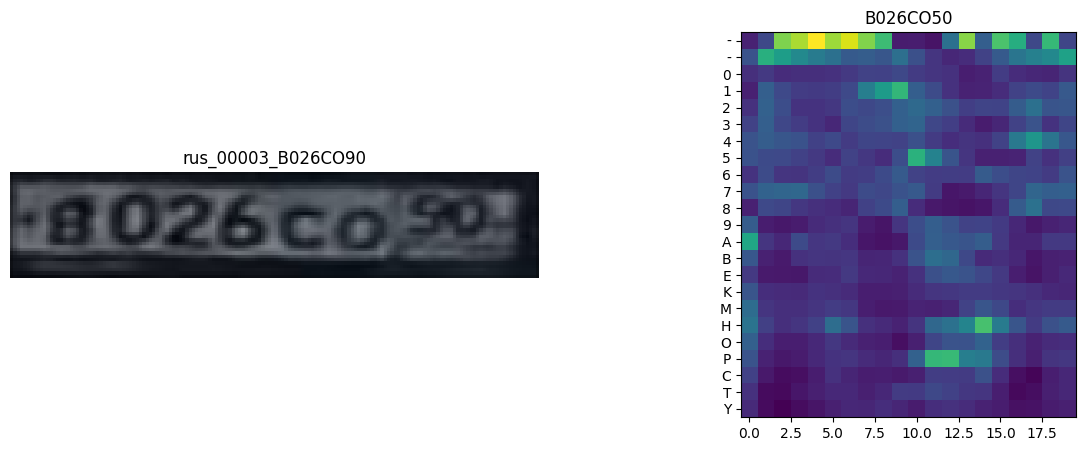

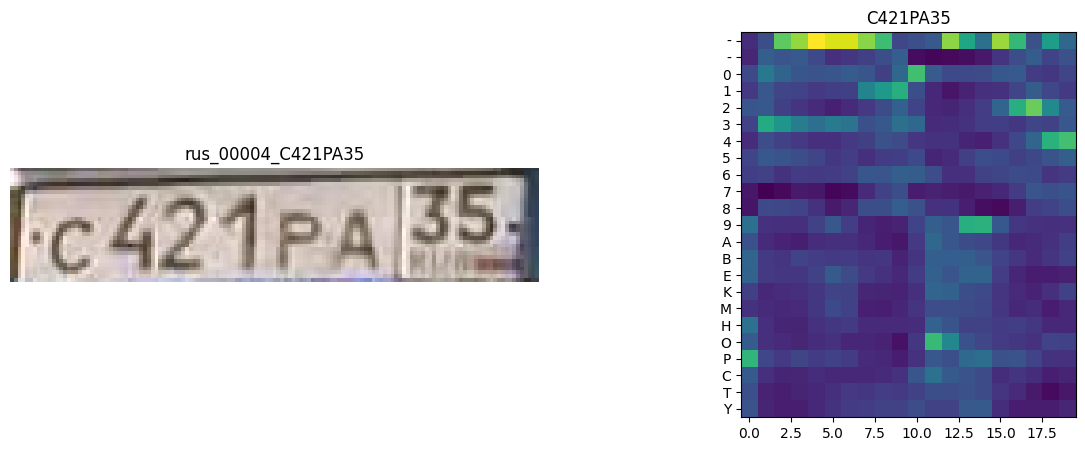

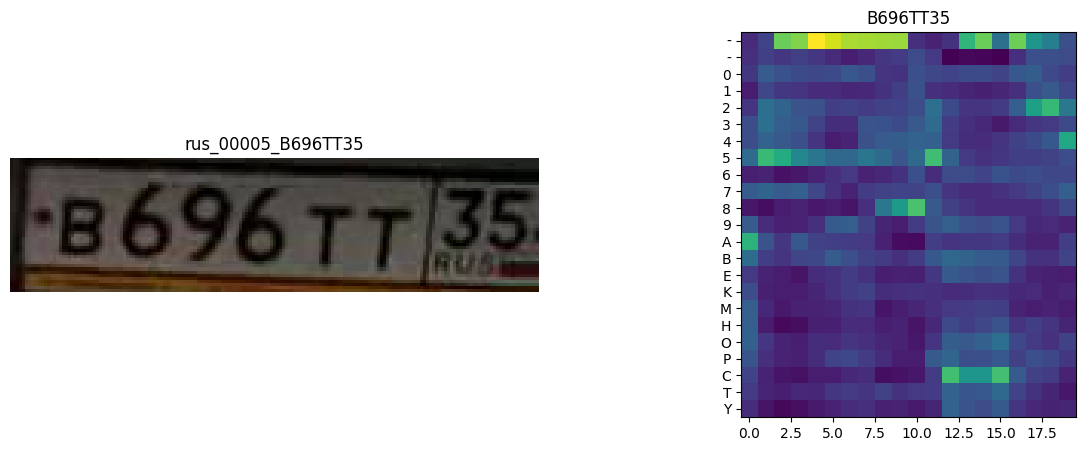

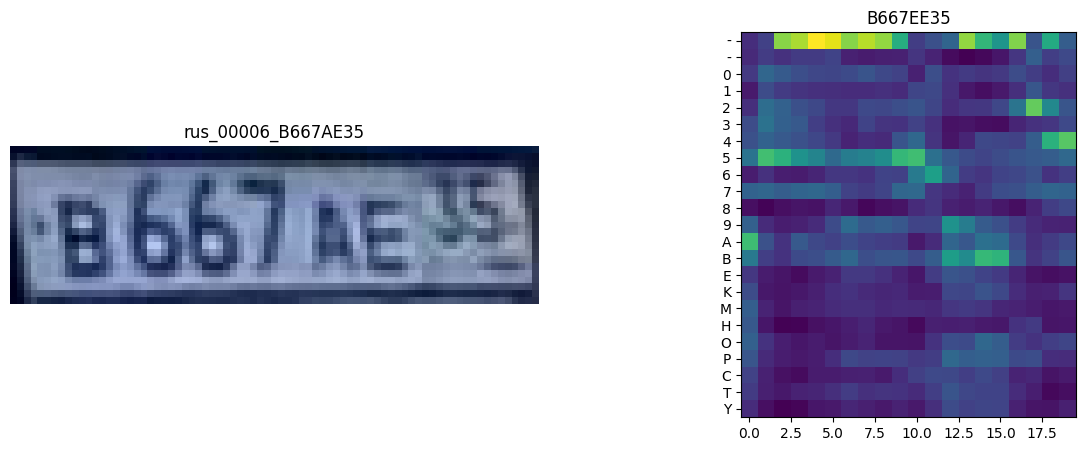

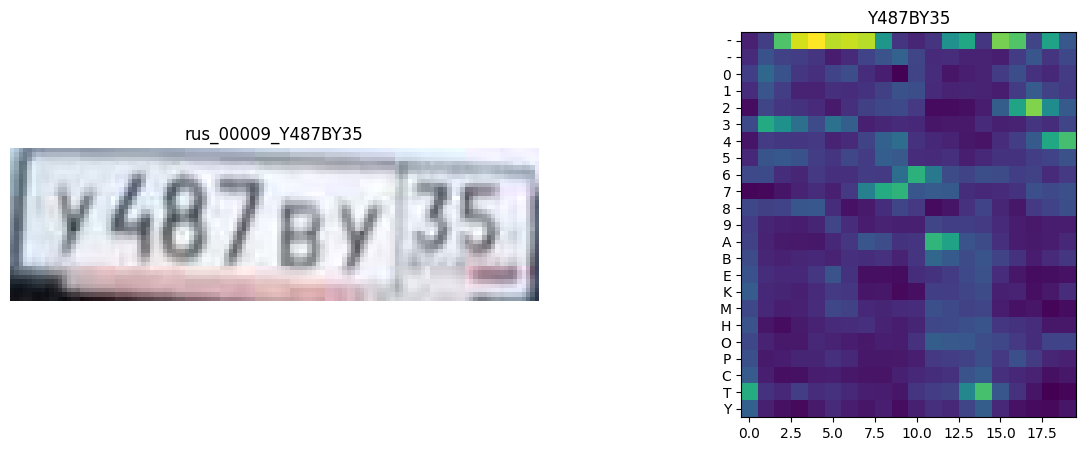

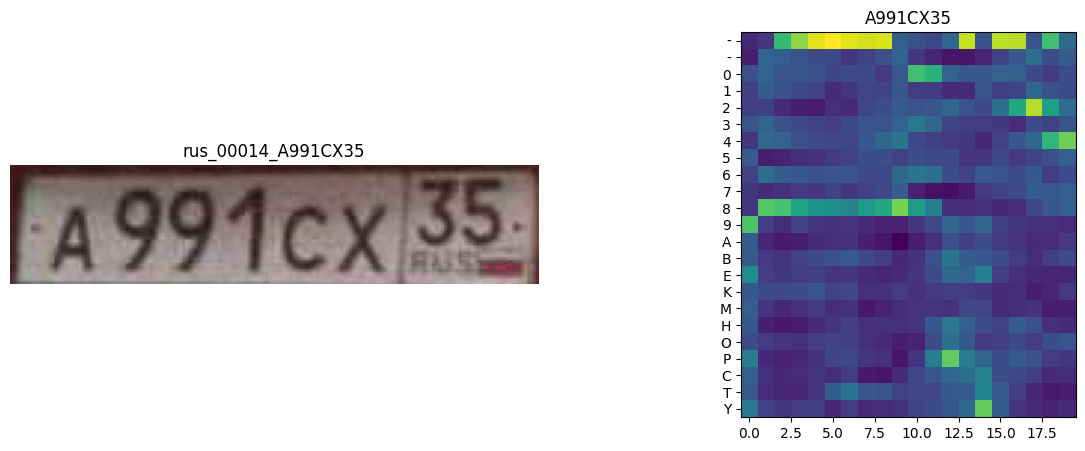

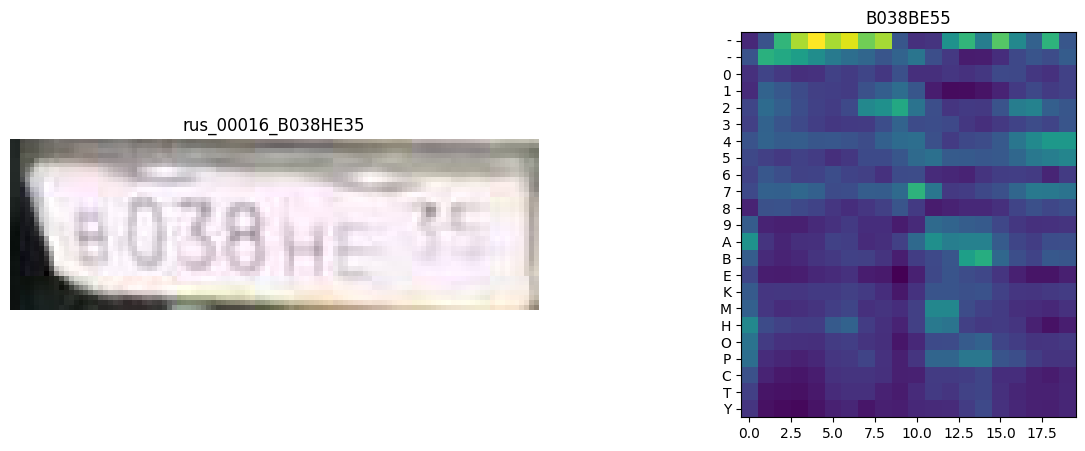

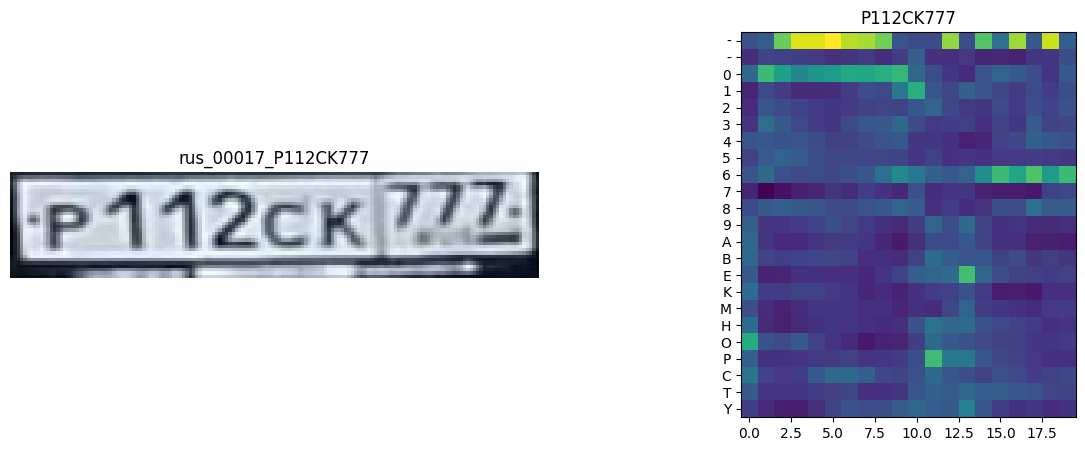

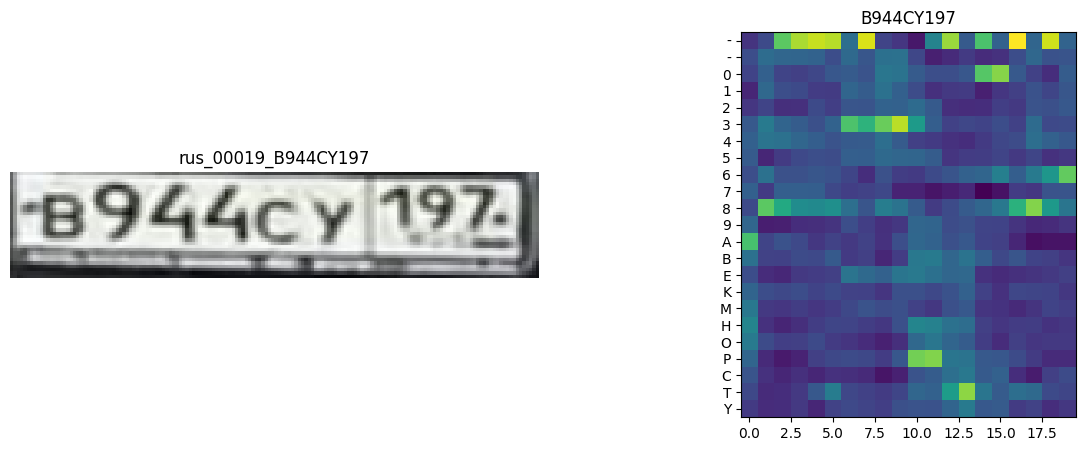

In [46]:
y_ticks = ["-"] + [x for x in ABC]
b = next(iter(dataloader))
torch_images = b["torch_images"]
pil_images   = b["pil_images"  ]
seqs_gt      = b["seq"         ]
seq_lens_gt  = b["seq_len"     ]
texts        = b["text"        ]

preds = crnn(torch_images.to(device)).cpu().detach()
texts_pred = decode(preds, ABC)

for i in range(9):
    plt.figure(figsize=(15, 5))
    pred_i = preds[:, i, :].T
    
    plt.subplot(1, 2, 1)
    pil_image = pil_images[i]
    plt.imshow(pil_image)
    plt.axis("off")
    plt.title(texts[i])

    plt.subplot(1, 2, 2)
    plt.yticks(range(pred_i.size(0)+1), y_ticks)
    plt.imshow(pred_i)
    plt.title(texts_pred[i])

    plt.show()


Пример визуализации

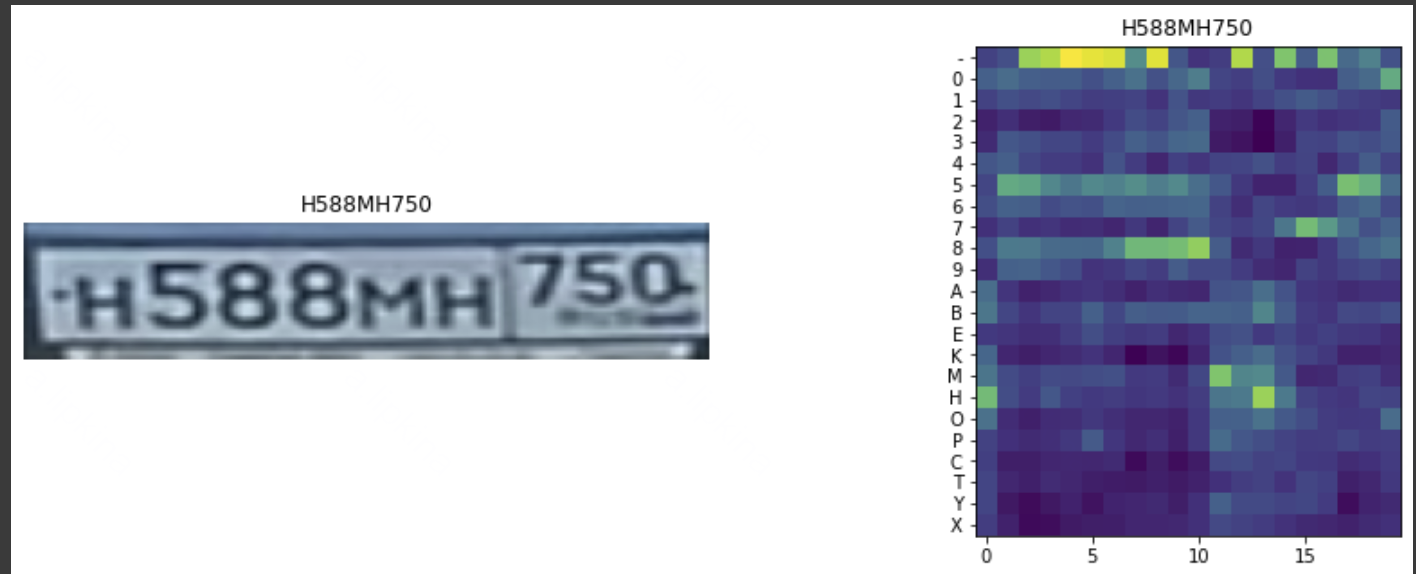

---

Frame 2087329782.png